In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

data_dir = '/home/ihor/projects/MLGuessQC/datasets/OMol25_dft_acceleration_estimate_results_pyscf/omol25_pyscf_results'
npz_files = [os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.npz')]
loaded_data = [np.load(f, allow_pickle=True) for f in npz_files]

In [9]:
for key in loaded_data[0].keys():
    print(f"{key}")

atomic_numbers
positions
init_dm
final_dm
final_mo_energy
final_mo_coeff
final_energy
n_scf_iter
calc_time
charge
spin
OMol25_n_scf_steps
OMol25_data_id
OMol25_source


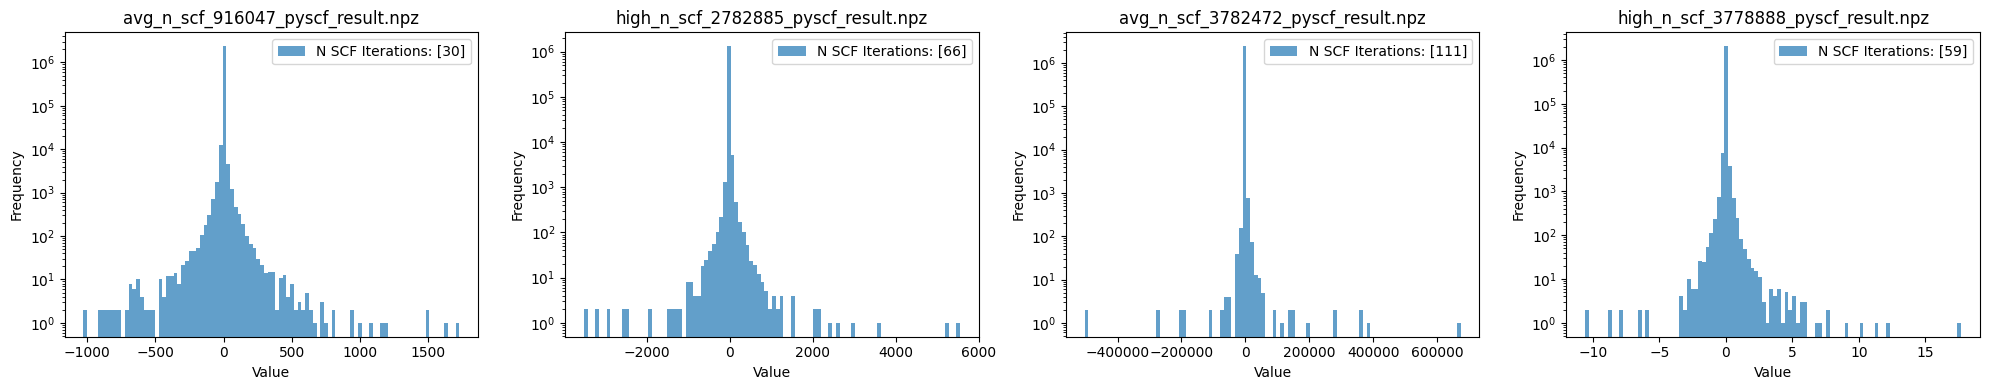

In [ ]:
fig, axes = plt.subplots(1, len(loaded_data), figsize=(5 * len(loaded_data), 4))
if len(loaded_data) == 1:
    axes = [axes]
for idx, (d, ax) in enumerate(zip(loaded_data, axes)):
    final_dm = d['final_dm']
    n_scf_iter = d['n_scf_iter']
    ax.hist(final_dm.flatten(), bins=100, label=f"N SCF Iterations: {n_scf_iter}", alpha=0.7)
    ax.set_title(f'{os.path.basename(npz_files[idx])}')
    ax.set_xlabel('Value')
    ax.set_yscale('log')
    ax.set_ylabel('Frequency')
    ax.legend()
plt.tight_layout()
plt.show()

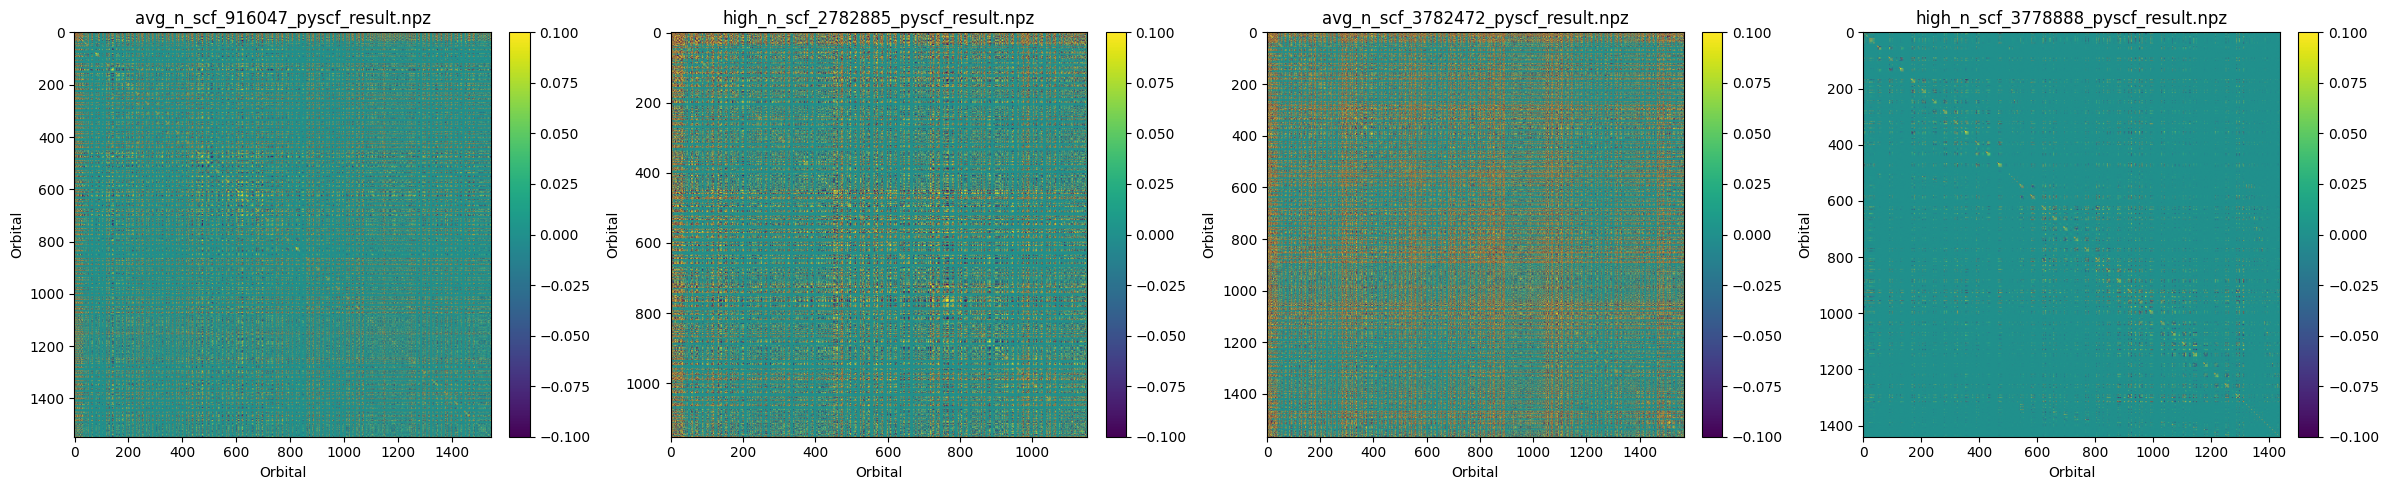

In [17]:
fig, axes = plt.subplots(1, len(loaded_data), figsize=(6 * len(loaded_data), 5))
if len(loaded_data) == 1:
    axes = [axes]
for idx, (d, ax) in enumerate(zip(loaded_data, axes)):
    final_dm = d['final_dm']
    im = ax.imshow(final_dm, aspect='auto', cmap='viridis', vmin=-0.1, vmax=0.1)
    ax.set_title(os.path.basename(npz_files[idx]))
    ax.set_xlabel('Orbital')
    ax.set_ylabel('Orbital')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig('final_dm_heatmaps.png', dpi=300)

In [18]:
loaded_data[-1]['atomic_numbers']

array([26,  8,  6,  8,  6,  6,  6,  6,  6,  7,  6,  8,  8,  1,  1,  1,  1,
        6,  8,  6,  6,  6,  6,  6,  6,  7,  7,  6,  6,  8,  6,  6,  6,  6,
        6,  6,  6,  6,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

In [22]:
N_s = 1
N_p = 3 
N_d = 5
N_f = 7
n_orbitals = {
    26: 6 * N_s + 5 * N_p + 4 * N_d + 1 * N_f,  # Fe
    8: 6 * N_s + 4 * N_p + 3 * N_d + 1 * N_f,  # O
    7: 6 * N_s + 3 * N_p + 3 * N_d + 1 * N_f,  # N
    6: 6 * N_s + 3 * N_p + 3 * N_d + 1 * N_f,  # C
    1: 3 * N_s + 2 * N_p, # H
}

In [23]:
n_orb_total = 0
for element in loaded_data[-1]['atomic_numbers']:
    n_orb = n_orbitals.get(element, None)
    if n_orb is not None:
        n_orb_total += n_orb
    else:
        print(f"Element {element} not found in n_orbitals dictionary.")

In [25]:
n_orb_total

1440

In [26]:
loaded_data[-1]['final_dm'].shape

(1440, 1440)

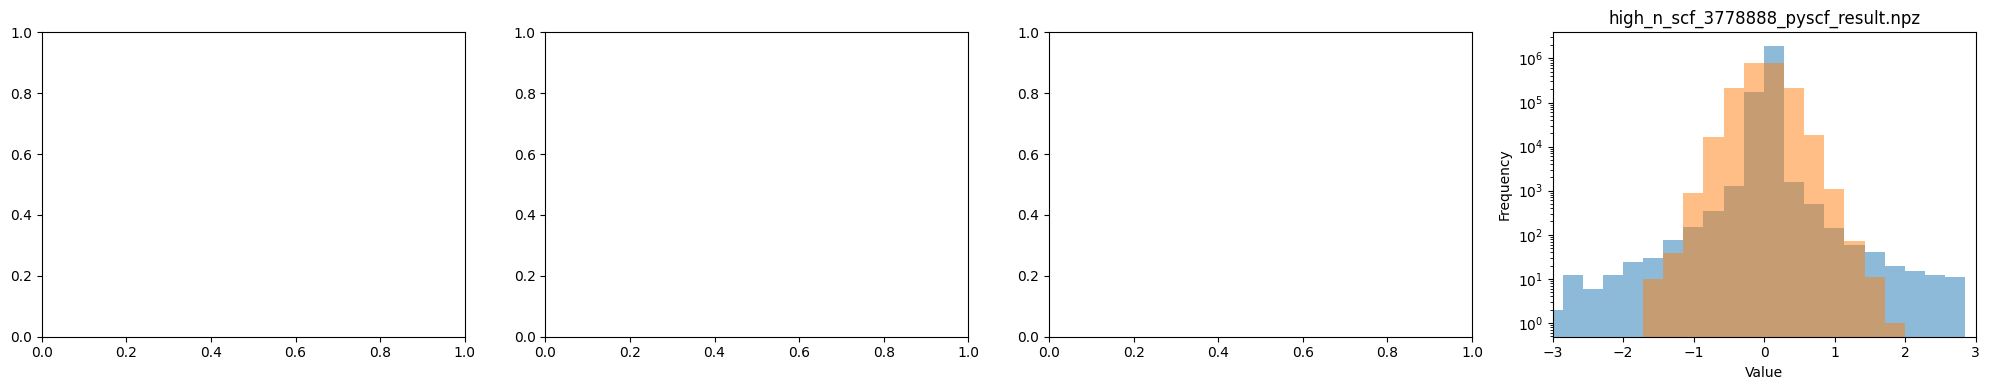

In [69]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(loaded_data), figsize=(5 * len(loaded_data), 4))
if len(loaded_data) == 1:
    axes = [axes]
for idx, (d, ax) in enumerate(zip(loaded_data, axes)):
    if idx < 3:
        continue
    final_dm = d['final_dm']
    n_scf_iter = d['n_scf_iter']
    # Compute bins based on the combined range of both datasets
    data_flat = final_dm.flatten()
    POW = 1/5
    data_pow = data_flat.copy()
    data_pow[data_pow >=0] = np.power(data_pow[data_pow >= 0], POW)
    data_pow[data_pow < 0] = -np.power(-data_pow[data_pow < 0], POW)
    min_val = min(data_flat.min(), data_pow.min())
    max_val = max(data_flat.max(), data_pow.max())
    bins = np.linspace(min_val, max_val, 100)
    ax.hist(data_flat, bins=bins, label=f"Raw (N SCF Iterations: {n_scf_iter})", alpha=0.5)
    ax.hist(data_pow, bins=bins, label=f"arcsinh (N SCF Iterations: {n_scf_iter})", alpha=0.5)
    ax.set_title(f'{os.path.basename(npz_files[idx])}')
    ax.set_xlabel('Value')
    ax.set_yscale('log')
    ax.set_ylabel('Frequency')
    ax.set_xlim(-3, 3)
    #ax.legend()
plt.tight_layout()
plt.show()

In [48]:
np.sinh(1e-5)

1.0000000000166668e-05

# ESCN Predictions

In [2]:
escn_out = np.load('/home/ihor/projects/MLGuessQC/mlguess/results/OMol25_veff/veff_epoch_1040.npz')

In [19]:
for key in escn_out.keys():
    print(key)

n_atom
atom_types
coords
ground_truth
predictions


In [5]:
veff_target = escn_out['ground_truth']
veff_pred = escn_out['predictions']

In [6]:
side_len = int(np.sqrt(veff_target.size))
veff_target = veff_target.reshape((side_len, side_len))
veff_pred = veff_pred.reshape((side_len, side_len))

In [7]:
np.diag(veff_target)

array([117.64395 ,  89.41839 ,  66.51722 , ...,  31.701231,  32.484688,
        32.527325], dtype=float32)

In [8]:
np.diag(veff_pred)

array([117.91528 ,  90.686646,  69.63888 , ...,  31.937998,  36.287663,
        33.001568], dtype=float32)

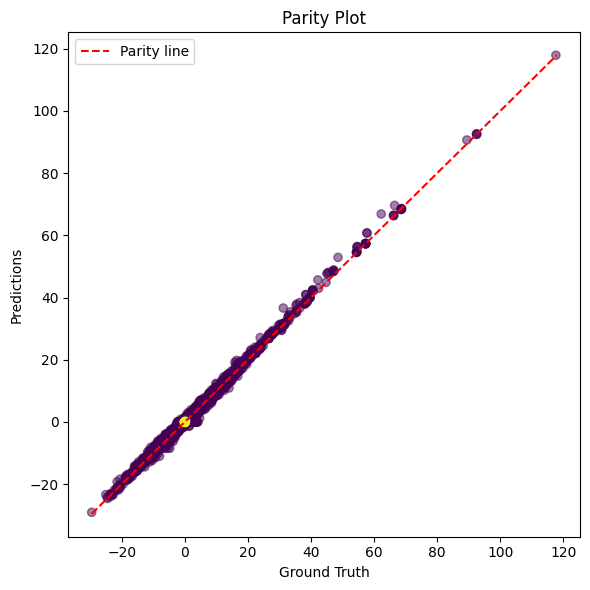

In [20]:
ground_truth = escn_out['ground_truth'][:100000]
predictions = escn_out['predictions'][:100000]

xy = np.vstack([ground_truth, predictions])
z = gaussian_kde(xy)(xy)

plt.figure(figsize=(6, 6))
plt.scatter(ground_truth, predictions, alpha=0.5, c=z, cmap='viridis')
min_val = min(ground_truth.min(), predictions.min())
max_val = max(ground_truth.max(), predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Parity line')
plt.xlabel('Ground Truth')
plt.ylabel('Predictions')
plt.title('Parity Plot')
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
veff_target = escn_out['ground_truth']
veff_pred = escn_out['predictions']

# Reshape to a square matrix
side_len = int(np.sqrt(veff_target.size))
veff_target = veff_target.reshape((side_len, side_len))
veff_pred = veff_pred.reshape((side_len, side_len))

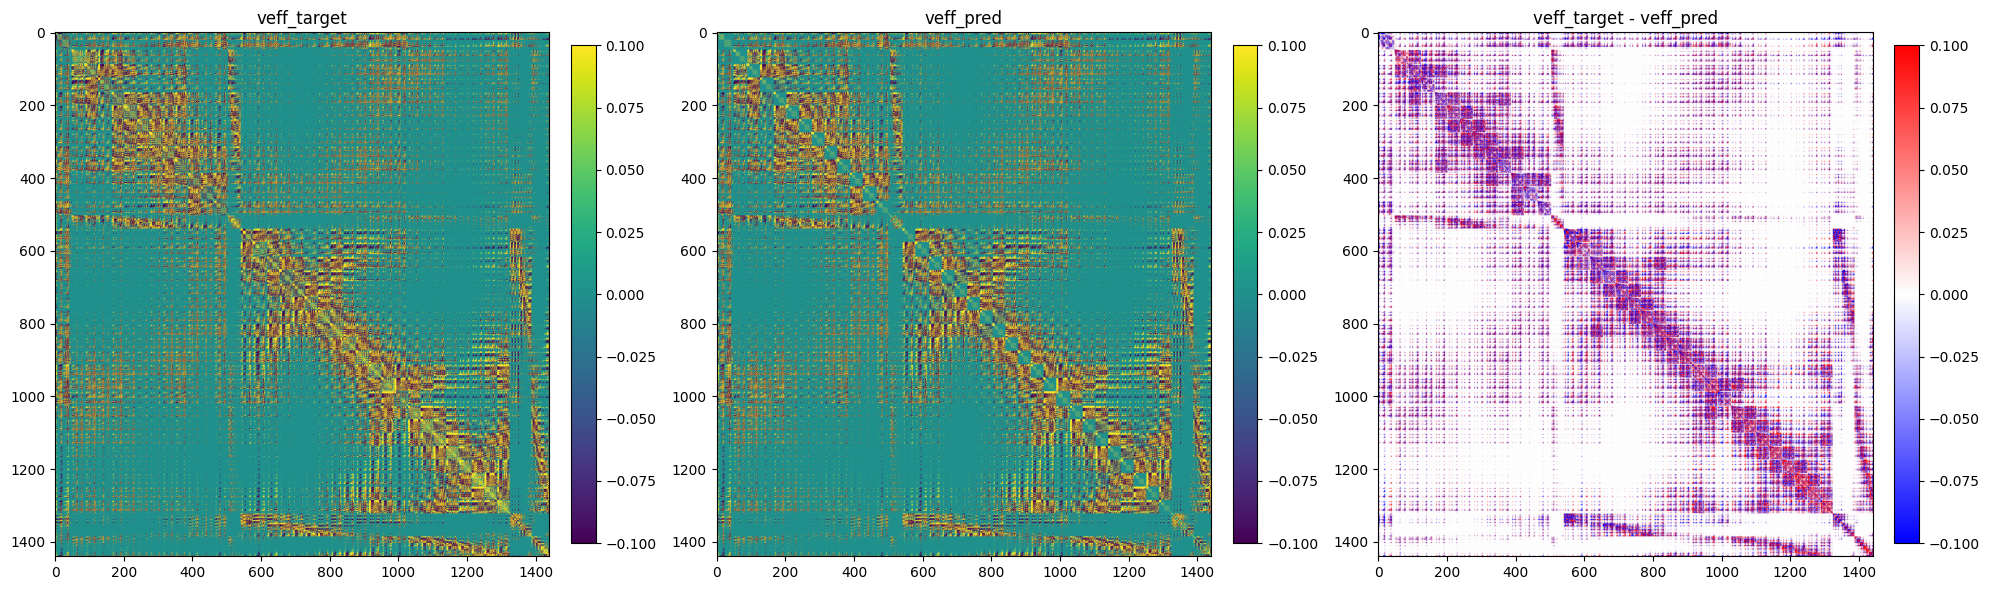

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

im0 = axes[0].imshow(veff_target, aspect='auto', cmap='viridis', vmin=-0.1, vmax=0.1)
axes[0].set_title('veff_target')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(veff_pred, aspect='auto', cmap='viridis', vmin=-0.1, vmax=0.1)
axes[1].set_title('veff_pred')
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

diff = veff_target - veff_pred
im2 = axes[2].imshow(diff, aspect='auto', cmap='bwr', vmin=-0.1, vmax=0.1)
axes[2].set_title('veff_target - veff_pred')
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [ ]:
import time
import lmdb
import pyscf
from tqdm import tqdm
from pyscf import lib
import numpy as np
import json 
import os

In [22]:
data = np.load('/home/ihor/projects/MLGuessQC/datasets/OMol25_debug/results/high_n_scf_3778888_pyscf_result_upd.npz', allow_pickle=True)

In [23]:
numbers = data["atomic_numbers"]
positions = data["positions"]

atom_symbols = [pyscf.gto.mole._symbol(int(num)) for num in numbers]
atom_positions = ["{:.8f} {:.8f} {:.8f}".format(*pos) for pos in positions]
atom_strings = [f"{symbol} {pos}" for symbol, pos in zip(atom_symbols, atom_positions)]
mol_string = "\n".join(atom_strings)
mol = pyscf.gto.Mole()
mol.atom = pyscf.gto.mole.fromstring(mol_string, format='raw')

mol.basis = 'def2tzvpd'
mol.verbose = 5
mol.spin = 0
mf = mol.KS()
mf.xc = 'wb97m_v'
mf.max_cycle = 0

System: uname_result(system='Linux', node='cleanenergy-gpu', release='6.8.0-60-generic', version='#63~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Tue Apr 22 19:00:15 UTC 2', machine='x86_64')  Threads 32
Python 3.10.16 (main, Dec 11 2024, 16:24:50) [GCC 11.2.0]
numpy 1.26.4  scipy 1.12.0  h5py 3.14.0
Date: Wed Jul  2 13:39:06 2025
PySCF version 2.9.0
PySCF path  /home/ihor/miniconda3/envs/mlguess_env/lib/python3.10/site-packages/pyscf

[CONFIG] conf_file None
[INPUT] verbose = 5
[INPUT] max_memory = 4000 
[INPUT] num. atoms = 51
[INPUT] num. electrons = 256
[INPUT] charge = 0
[INPUT] spin (= nelec alpha-beta = 2S) = 0
[INPUT] symmetry False subgroup None
[INPUT] Mole.unit = angstrom
[INPUT] Symbol           X                Y                Z      unit          X                Y                Z       unit  Magmom
[INPUT]  1 Fe     0.094957000000  -0.046777000000   0.549365000000 AA    0.179442723610  -0.088395718929   1.038149392422 Bohr   0.0
[INPUT]  2 O     -4.081120000000   0.931734000000

Initialize <pyscf.gto.mole.Mole object at 0x76c7b1643310> in <pyscf.dft.rks.RKS object at 0x76c7c8b8e080>


In [25]:
for key in data.keys():
    print(key)

atomic_numbers
positions
h1e
s1e
init_dm
final_dm
final_fock
final_veff
final_energy
n_scf_iter
calc_time
charge
spin
OMol25_n_scf_steps
OMol25_data_id
OMol25_source


In [37]:
orb_e_true, orb_coef_true = mf.eig(data['h1e'] + data['final_veff'], mf.get_ovlp())

In [38]:
orb_e_true

array([-256.55624274,  -30.24045637,  -26.01618306, ...,   45.06337798,
         45.19341352,   45.2091423 ])

In [39]:
orb_e, orb_coef = mf.eig(data['h1e'] + veff_pred, mf.get_ovlp())

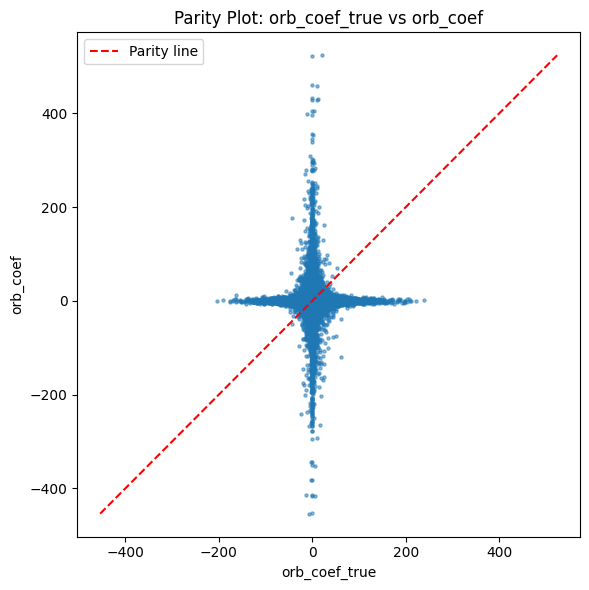

In [40]:
plt.figure(figsize=(6, 6))
plt.scatter(orb_coef_true.flatten(), orb_coef.flatten(), alpha=0.5, s=5)
min_val = min(orb_coef_true.min(), orb_coef.min())
max_val = max(orb_coef_true.max(), orb_coef.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Parity line')
plt.xlabel('orb_coef_true')
plt.ylabel('orb_coef')
plt.title('Parity Plot: orb_coef_true vs orb_coef')
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
grids = mf.initialize_grids()

In [49]:
mf.grids.weights.shape

(652672,)

In [53]:
mf.grids.coords.shape

(652672, 3)